# Unidad 5: Geometría de los Datos y Dimensionalidad
## Matemáticas para Análisis de Datos — ITEC

**Objetivos de esta notebook:**
- Calcular normas L1 y L2 de vectores de features
- Construir una matriz de distancias euclidianas entre puntos
- Implementar similitud del coseno para comparar observaciones
- Calcular autovalores y autovectores de una matriz de covarianza
- Aplicar PCA con scikit-learn y analizar la varianza explicada

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Dataset de casas
nombres = ['Casa A', 'Casa B', 'Casa C', 'Casa D', 'Casa E']
dataset = np.array([
    [120.0,  3.0,  2.5, 180000.0],
    [ 85.0,  2.0,  1.0, 150000.0],
    [200.0,  4.0,  5.0, 250000.0],
    [ 60.0,  1.0,  0.5, 120000.0],
    [150.0,  3.0,  3.2, 210000.0]
])

X = dataset[:, :3]   # features: size_m2, rooms, distance_km
y = dataset[:, 3]    # precios
feature_names = ['size_m2', 'rooms', 'distance_km']

## 1. Normas Vectoriales

La norma mide la "magnitud" o "longitud" de un vector.

In [3]:
# Normalizar primero (para que las unidades no dominen)
scaler = StandardScaler()
X_norm = scaler.fit_transform(X)

print("Normas de cada casa (espacio normalizado):")
print(f"{'Casa':>8} | {'L1 (Manhattan)':>16} | {'L2 (Euclidiana)':>16}")
print("-" * 46)
for i, nombre in enumerate(nombres):
    norma_l1 = np.linalg.norm(X_norm[i], ord=1)
    norma_l2 = np.linalg.norm(X_norm[i], ord=2)
    print(f"{nombre:>8} | {norma_l1:>16.4f} | {norma_l2:>16.4f}")

print("\n→ La norma es la 'distancia' de cada punto al origen del espacio de features")

Normas de cada casa (espacio normalizado):
    Casa |   L1 (Manhattan) |  L2 (Euclidiana)
----------------------------------------------
  Casa A |           0.4905 |           0.3987
  Casa B |           2.2555 |           1.3203
  Casa C |           4.5287 |           2.6201
  Casa D |           4.0551 |           2.3569
  Casa E |           1.4134 |           0.8235

→ La norma es la 'distancia' de cada punto al origen del espacio de features


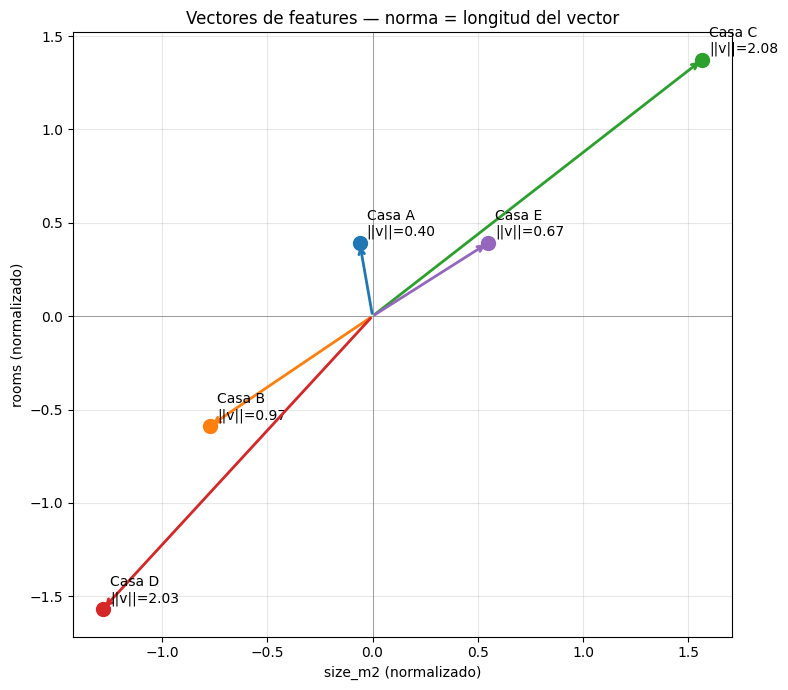

In [4]:
# Visualizar normas geométricamente en 2D (usando las primeras 2 features)
fig, ax = plt.subplots(figsize=(8, 7))

for i, nombre in enumerate(nombres):
    v = X_norm[i, :2]  # primeras 2 dims
    ax.annotate('', xy=v, xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color=f'C{i}', lw=2))
    ax.scatter(*v, s=100, color=f'C{i}', zorder=5)
    ax.annotate(f'{nombre}\n||v||={np.linalg.norm(v):.2f}', 
                v, textcoords='offset points', xytext=(5, 5))

ax.axhline(0, color='gray', linewidth=0.5)
ax.axvline(0, color='gray', linewidth=0.5)
ax.set_xlabel('size_m2 (normalizado)')
ax.set_ylabel('rooms (normalizado)')
ax.set_title('Vectores de features — norma = longitud del vector')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Distancia Euclidiana: ¿cuán similares son dos casas?

$$d(a, b) = ||a - b||_2 = \sqrt{\sum_i (a_i - b_i)^2}$$

In [5]:
# Calcular distancia entre todas las casas
n = len(X_norm)
dist_matrix = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        dist_matrix[i, j] = np.linalg.norm(X_norm[i] - X_norm[j])

print("Matriz de distancias euclidianas (espacio normalizado):")
print(f"{'':>8}", end='')
for n_str in nombres:
    print(f"{n_str:>9}", end='')
print()
for i, nombre in enumerate(nombres):
    print(f"{nombre:>8}", end='')
    for j in range(n):
        print(f"{dist_matrix[i,j]:>9.3f}", end='')
    print()

# Encontrar el par más similar
np.fill_diagonal(dist_matrix, np.inf)
i_min, j_min = np.unravel_index(dist_matrix.argmin(), dist_matrix.shape)
np.fill_diagonal(dist_matrix, 0)
print(f"\nEl par más similar: {nombres[i_min]} y {nombres[j_min]} (distancia={dist_matrix[i_min, j_min]:.3f})")

Matriz de distancias euclidianas (espacio normalizado):
           Casa A   Casa B   Casa C   Casa D   Casa E
  Casa A    0.000    1.528    2.453    2.623    0.749
  Casa B    1.528    0.000    3.935    1.147    2.139
  Casa C    2.453    3.935    0.000    4.957    1.801
  Casa D    2.623    1.147    4.957    0.000    3.164
  Casa E    0.749    2.139    1.801    3.164    0.000

El par más similar: Casa A y Casa E (distancia=0.749)


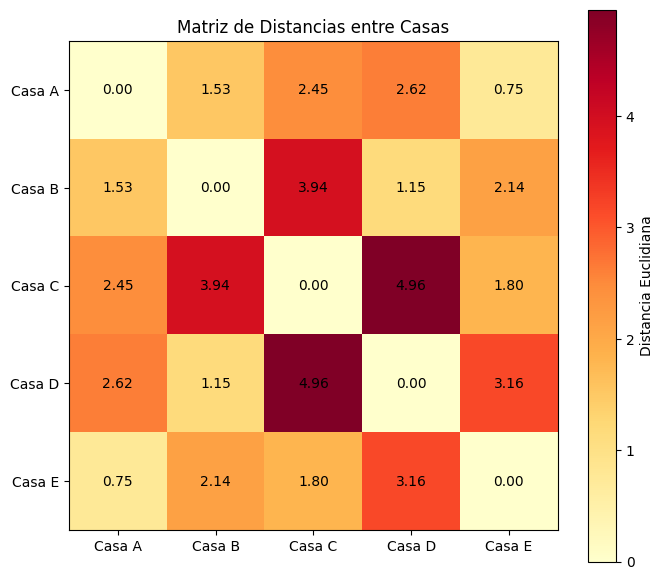

In [6]:
# Heatmap de la matriz de distancias
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(dist_matrix, cmap='YlOrRd')
plt.colorbar(im, ax=ax, label='Distancia Euclidiana')
ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels(nombres)
ax.set_yticklabels(nombres)
for i in range(n):
    for j in range(n):
        ax.text(j, i, f'{dist_matrix[i,j]:.2f}', ha='center', va='center', fontsize=10)
ax.set_title('Matriz de Distancias entre Casas')
plt.tight_layout()
plt.show()

## 3. Similitud del Coseno

Mide el ángulo entre vectores, independientemente de su magnitud.

$$\cos(\theta) = \frac{a \cdot b}{||a||_2 \cdot ||b||_2}$$

In [7]:
def cosine_similarity(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

# Matriz de similitud del coseno
sim_matrix = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        sim_matrix[i, j] = cosine_similarity(X_norm[i], X_norm[j])

print("Matriz de Similitud del Coseno:")
print(f"{'':>8}", end='')
for n_str in nombres:
    print(f"{n_str:>9}", end='')
print()
for i, nombre in enumerate(nombres):
    print(f"{nombre:>8}", end='')
    for j in range(n):
        print(f"{sim_matrix[i,j]:>9.3f}", end='')
    print()

print("\n→ 1.0 = idéntica dirección (muy similares)")
print("→ 0.0 = perpendiculares (sin relación)")
print("→ -1.0 = opuestos (muy distintas)")

Matriz de Similitud del Coseno:
           Casa A   Casa B   Casa C   Casa D   Casa E
  Casa A    1.000   -0.412    0.481   -0.619    0.420
  Casa B   -0.412    1.000   -0.994    0.961   -0.991
  Casa C    0.481   -0.994    1.000   -0.984    0.996
  Casa D   -0.619    0.961   -0.984    1.000   -0.973
  Casa E    0.420   -0.991    0.996   -0.973    1.000

→ 1.0 = idéntica dirección (muy similares)
→ 0.0 = perpendiculares (sin relación)
→ -1.0 = opuestos (muy distintas)


In [8]:
# Sistema de recomendación simple: dada una casa nueva, encontrar la más similar
casa_nueva = np.array([110.0, 3.0, 2.0])  # nueva casa: 110m², 3 hab, 2km
casa_nueva_norm = (casa_nueva - scaler.mean_) / scaler.scale_

similaridades = [cosine_similarity(casa_nueva_norm, X_norm[i]) for i in range(n)]

print("Similitud de la casa nueva [110m², 3hab, 2km] con cada casa del dataset:")
for nombre, sim in zip(nombres, similaridades):
    barra = '█' * int(sim * 20)
    print(f"  {nombre}: {sim:.4f}  {barra}")

recomendacion = nombres[np.argmax(similaridades)]
print(f"\nCasa más similar: {recomendacion}")

Similitud de la casa nueva ², 3hab, 2km] con cada casa del dataset:
  Casa A: 0.7338  ██████████████
  Casa B: 0.3021  ██████
  Casa C: -0.2166  
  Casa D: 0.0409  
  Casa E: -0.2675  

Casa más similar: Casa A


## 4. Autovalores y Autovectores de la Covarianza

Los autovectores de la matriz de covarianza apuntan en las **direcciones de mayor varianza** del dataset.

In [9]:
# Matriz de covarianza
cov = np.cov(X_norm.T)  # (3, 3)
print("Matriz de covarianza (features normalizadas):")
print(cov.round(4))
print("(diagonal: varianza de cada feature; fuera de diagonal: covarianza entre features)")

Matriz de covarianza (features normalizadas):
[[1.25   1.202  1.2454]
 [1.202  1.25   1.1993]
 [1.2454 1.1993 1.25  ]]
(diagonal: varianza de cada feature; fuera de diagonal: covarianza entre features)


In [10]:
# Calcular autovalores y autovectores
eigenvalues, eigenvectors = np.linalg.eigh(cov)  # eigh para matrices simétricas

# Ordenar de mayor a menor
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

varianza_total = eigenvalues.sum()
varianza_explicada = eigenvalues / varianza_total

print("Autovalores y varianza explicada:")
for i, (val, pct) in enumerate(zip(eigenvalues, varianza_explicada)):
    print(f"  Componente {i+1}: autovalor={val:.4f}  |  varianza={pct*100:.1f}%")
    print(f"    Autovector: {eigenvectors[:, i].round(3)}")

print(f"\nLas 2 primeras componentes explican el {varianza_explicada[:2].sum()*100:.1f}% de la varianza")

Autovalores y varianza explicada:
  Componente 1: autovalor=3.6812  |  varianza=98.2%
    Autovector: [-0.58  -0.573 -0.58 ]
  Componente 2: autovalor=0.0642  |  varianza=1.7%
    Autovector: [ 0.386 -0.82   0.423]
  Componente 3: autovalor=0.0046  |  varianza=0.1%
    Autovector: [-0.717  0.021  0.697]

Las 2 primeras componentes explican el 99.9% de la varianza


## 5. PCA con scikit-learn

In [11]:
# PCA con sklearn (mismo resultado, más conveniente)
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_norm)

print("Varianza explicada por cada componente (sklearn):")
for i, ratio in enumerate(pca.explained_variance_ratio_):
    acum = pca.explained_variance_ratio_[:i+1].sum()
    barra = '█' * int(ratio * 40)
    print(f"  PC{i+1}: {ratio*100:5.1f}%  (acumulado: {acum*100:.1f}%)  {barra}")

print("\nComponentes principales (loadings):")
for i, comp in enumerate(pca.components_):
    print(f"  PC{i+1}: ", end='')
    for fname, val in zip(feature_names, comp):
        print(f"{fname}={val:+.3f}  ", end='')
    print()

Varianza explicada por cada componente (sklearn):
  PC1:  98.2%  (acumulado: 98.2%)  ███████████████████████████████████████
  PC2:   1.7%  (acumulado: 99.9%)  
  PC3:   0.1%  (acumulado: 100.0%)  

Componentes principales (loadings):
  PC1: size_m2=+0.580  rooms=+0.573  distance_km=+0.580  
  PC2: size_m2=-0.386  rooms=+0.820  distance_km=-0.423  
  PC3: size_m2=+0.717  rooms=-0.021  distance_km=-0.697  


/var/folders/n8/0dv0wdc16nv4c60t2qxyb1k00000gn/T/ipykernel_17244/4189113958.py:32: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


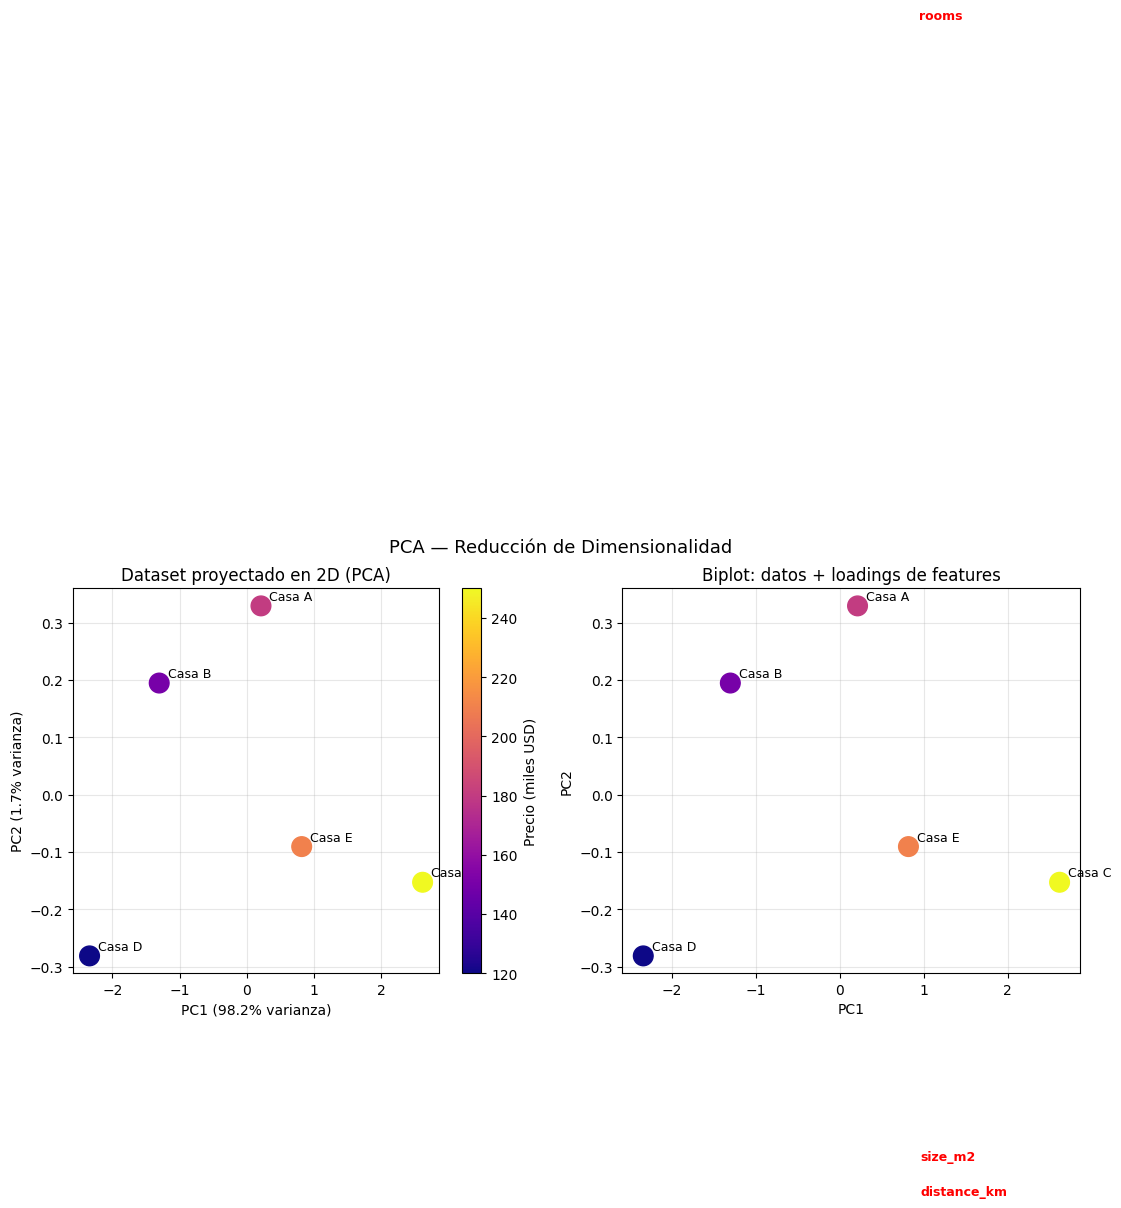

In [12]:
# Proyección en 2D con PCA
pca_2d = PCA(n_components=2)
X_2d = pca_2d.fit_transform(X_norm)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Scatter de las 2 primeras componentes principales
scatter = axes[0].scatter(X_2d[:, 0], X_2d[:, 1], c=y/1000, cmap='plasma', s=200, zorder=5)
for i, nombre in enumerate(nombres):
    axes[0].annotate(nombre, X_2d[i], textcoords='offset points', xytext=(6, 4), fontsize=9)
plt.colorbar(scatter, ax=axes[0], label='Precio (miles USD)')
axes[0].set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% varianza)')
axes[0].set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% varianza)')
axes[0].set_title('Dataset proyectado en 2D (PCA)')
axes[0].grid(True, alpha=0.3)

# Biplot: loadings
axes[1].scatter(X_2d[:, 0], X_2d[:, 1], c=y/1000, cmap='plasma', s=200, zorder=5)
for i, nombre in enumerate(nombres):
    axes[1].annotate(nombre, X_2d[i], textcoords='offset points', xytext=(6, 4), fontsize=9)
for i, fname in enumerate(feature_names):
    loading = pca_2d.components_[:, i] * 1.5
    axes[1].annotate('', xy=loading, xytext=(0, 0),
                     arrowprops=dict(arrowstyle='->', color='red', lw=2))
    axes[1].text(loading[0]*1.1, loading[1]*1.1, fname, color='red', fontsize=9, fontweight='bold')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].set_title('Biplot: datos + loadings de features')
axes[1].grid(True, alpha=0.3)

plt.suptitle('PCA — Reducción de Dimensionalidad', fontsize=13)
plt.tight_layout()
plt.show()

## Ejercicios

**Ejercicio 1:** Calculá la distancia euclidiana entre la Casa A y una casa nueva con features `[130, 3, 2.0]`. ¿Cuál casa del dataset es la más cercana a esta nueva casa?

**Ejercicio 2:** Agregá una cuarta feature al dataset: `age_years = [10, 5, 20, 15, 3]`. Aplicá PCA. ¿Cuántas componentes necesitás para explicar el 90% de la varianza?

**Ejercicio 3 (desafío):** Implementá K-Nearest Neighbors (k=1) usando la distancia euclidiana calculada manualmente. Dado un nuevo punto, encontrá el vecino más cercano y usá su precio como predicción.

In [13]:
# Ejercicio 1


In [14]:
# Ejercicio 2


In [ ]:
# Ejercicio 3    


In [20]:
v = np.array([3, -4])

print(np.linalg.norm(v))

5.0
